In [1]:
#importing model and predicting validation dataset
# Summary of statistics 
import json
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import classification_report

from fftdeep.data.arrays import get_arrays
from fftdeep.evaluation.metrics import (
    binary_metrics, youden_threshold, plot_confusion, plot_history, plot_roc,
)
from fftdeep.paths import PROJECT_ROOT

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

Xva, yva = get_arrays("val")
Xva = Xva.astype("float32")
model = keras.models.load_model(PROJECT_ROOT / "models" / "cnn_baseline.keras", compile=False)
probs = model.predict(Xva, batch_size=512, verbose=0).ravel()
print(probs.shape, probs.min(), probs.max())

(19741,) 3.76605e-08 1.0


In [2]:
m = binary_metrics(yva, probs)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in m.items()})
print(classification_report(yva, (probs >= 0.5).astype(int),
                            target_names=["REAL", "FAKE"], digits=4))

{'threshold': 0.5, 'accuracy': 0.9474, 'precision': 0.9422, 'recall': 0.9519, 'specificity': 0.9431, 'f1': 0.947, 'roc_auc': 0.9881, 'tn': 9431, 'fp': 569, 'fn': 469, 'tp': 9272}
              precision    recall  f1-score   support

        REAL     0.9526    0.9431    0.9478     10000
        FAKE     0.9422    0.9519    0.9470      9741

    accuracy                         0.9474     19741
   macro avg     0.9474    0.9475    0.9474     19741
weighted avg     0.9475    0.9474    0.9474     19741



24 epochs ran


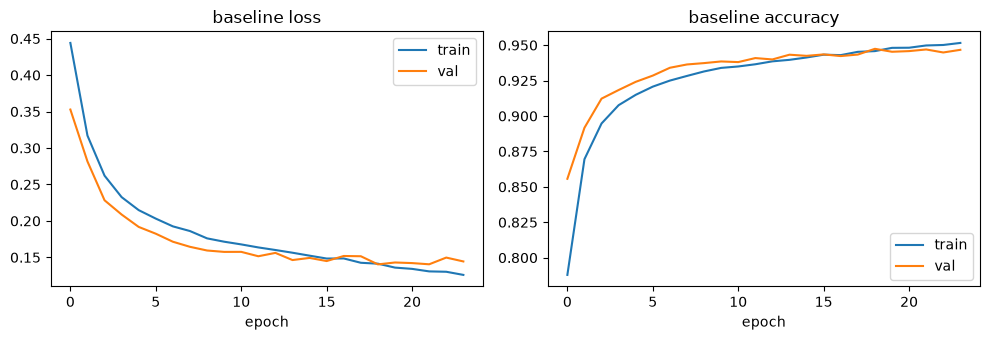

In [3]:
hist = json.loads((PROJECT_ROOT / "reports" / "history_baseline.json").read_text())
print(len(hist["loss"]), "epochs ran")
fig = plot_history(hist, "baseline")
fig.savefig(FIG_DIR / "baseline_history.png", dpi=150, bbox_inches="tight")
plt.show()

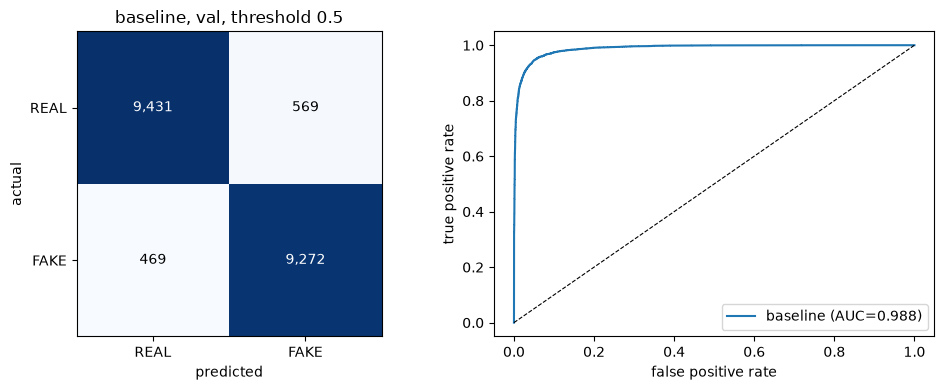

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion(m, axes[0], "baseline, val, threshold 0.5")
plot_roc(yva, probs, "baseline", axes[1])
fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_val_confusion_roc.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
t = youden_threshold(yva, probs)
m_t = binary_metrics(yva, probs, t)
print(round(t, 4), {k: round(v, 4) if isinstance(v, float) else v for k, v in m_t.items()})

0.5515 {'threshold': 0.5515, 'accuracy': 0.9479, 'precision': 0.9476, 'recall': 0.9468, 'specificity': 0.949, 'f1': 0.9472, 'roc_auc': 0.9881, 'tn': 9490, 'fp': 510, 'fn': 518, 'tp': 9223}
